## Boxplot

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/ab-test.csv")
df.head()

,uid,diff,time,group
0,user_1,-103.333333,after,test
1,user_1,-6.000000,before,test
2,user_18,-10.000000,after,test
3,user_18,-3.500000,before,test
4,user_19,-82.333333,after,test


In [ ]:
df_before = [
    df[(df['group']=='control') & (df['time']=='before')]['diff'],
    df[(df['group']=='test') & (df['time']=='before')]['diff']
]
df[(df['group']=='control') & (df['time']=='before')]['diff'].info()

AttributeError: 'Series' object has no attribute 'imfo'

C:\Users\user\AppData\Local\Temp\ipykernel_7868\3670578504.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_before = ax_before.boxplot(df_before, labels=labels_before, whiskerprops={'color':'red', 'linewidth':1},
C:\Users\user\AppData\Local\Temp\ipykernel_7868\3670578504.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_after = ax_after.boxplot(df_after, labels=labels_after, whiskerprops={'color':'red', 'linewidth':1},


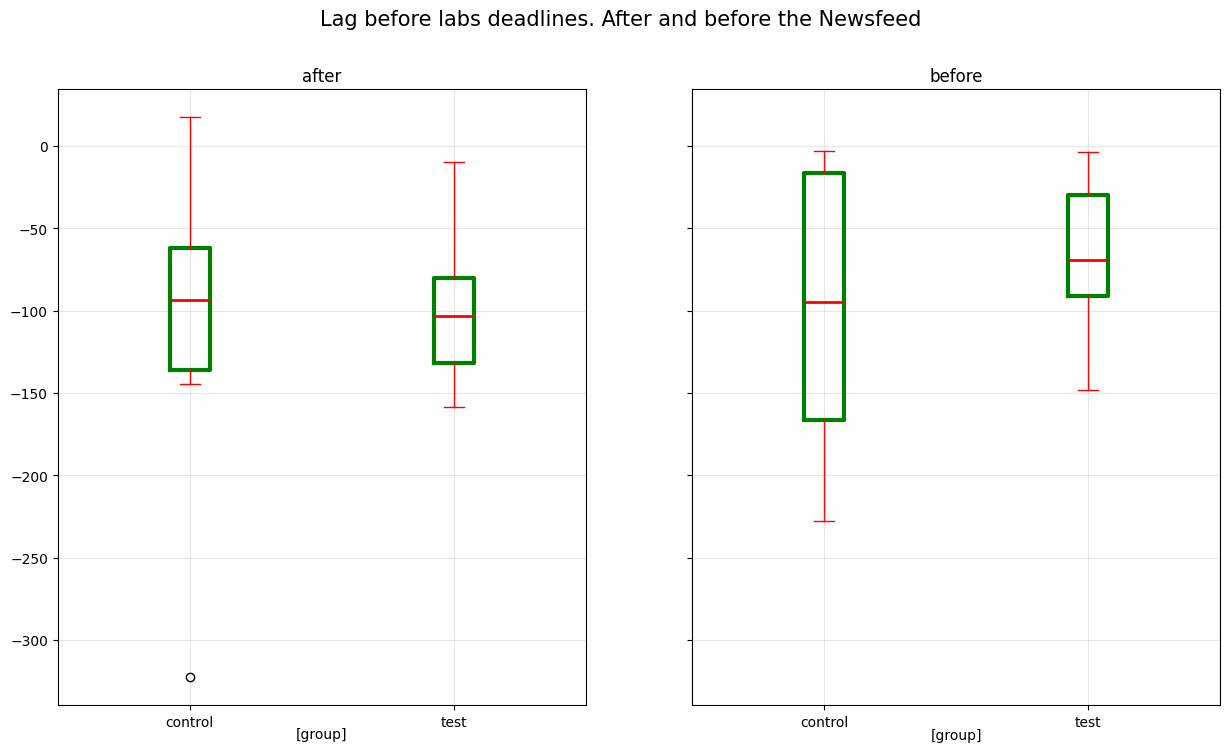

In [ ]:
fig, (ax_after, ax_before) = plt.subplots(1, 2, figsize=(15, 8), sharey=True)

colors = {'control': 'lightblue', 'test': 'lightcoral'}
df_before = [
    df[(df['group']=='control') & (df['time']=='before')]['diff'],
    df[(df['group']=='test') & (df['time']=='before')]['diff']
]
labels_before = ['control', 'test']
box_before = ax_before.boxplot(df_before, labels=labels_before, whiskerprops={'color':'red', 'linewidth':1},
                                boxprops={'linewidth':3, 'color':'green'}, medianprops=dict(linewidth = 2, color = 'red'),
                                capprops=dict(color='red', linewidth=1),)
ax_before.set_title('before')
ax_before.grid(True, alpha=0.3)
ax_before.text(1.5,
        ax_before.get_ylim()[0] - 121,
        '[group]',
        ha='center')


df_after = [
    df[(df['group']=='control') & (df['time']=='after')]['diff'],
    df[(df['group']=='test') & (df['time']=='after')]['diff']
]
labels_after = ['control', 'test']
box_after = ax_after.boxplot(df_after, labels=labels_after, whiskerprops={'color':'red', 'linewidth':1},
                            boxprops={'linewidth':3, 'color':'green'}, medianprops=dict(linewidth = 2, color = 'red'),
                            capprops=dict(color='red', linewidth=1))
ax_after.set_title('after')
ax_after.grid(True, alpha=0.3)
ax_after.text(1.5,
        ax_after.get_ylim()[0] - 20,
        '[group]',
        ha='center')

fig.suptitle('Lag before labs deadlines. After and before the Newsfeed', fontsize=15)
plt.show()


## What was the IQR of the control group before the newsfeed?

Answer: 150.0

In [14]:
control_before = df[(df['group'] == 'control') & (df['time'] == 'before')]['diff']
Q1 = control_before.quantile(0.25)
Q3 = control_before.quantile(0.75)
IQR_exact = Q3 - Q1
IQR_approx = round(IQR_exact / 10) * 10

print(f"IQR for control before: {IQR_exact}")

IQR for control before: 150.0
